# Phase 1 — Traffic Detection Dataset: Download, Explore & Prepare

**Environment:** Google Colab (T4 GPU recommended)  
**Dataset:** [Traffic Detection Project](https://www.kaggle.com/datasets/yusufberksardoan/traffic-detection-project) — 6,552 images, real traffic camera perspective, YOLO format labels  
**Goal:** Verify the dataset, visualise class distribution and sample frames, remap classes to our 4-class schema, and save to Google Drive for Phase 2 training.

## 1. Mount Google Drive

In [1]:
import os, sys

IN_COLAB = 'google.colab' in sys.modules or 'COLAB_BACKEND_VERSION' in os.environ

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_BASE = '/content/drive/MyDrive/TrafficVision'
    RAW_DIR    = '/content/traffic_raw'
    OUT_DIR    = '/content/traffic_yolo'
    CLIP_DIR   = '/content/sample_clips'
else:
    _repo      = os.path.abspath(os.path.join(os.getcwd(), '..'))
    DRIVE_BASE = os.path.join(_repo, 'data', 'TrafficVision')
    RAW_DIR    = os.path.join(_repo, 'data', 'traffic_raw')
    OUT_DIR    = os.path.join(_repo, 'data', 'traffic_yolo')
    CLIP_DIR   = os.path.join(_repo, 'data', 'sample_videos')
    print('[LOCAL MODE] Outputs will go to data/')

DRIVE_DATASET_DIR = os.path.join(DRIVE_BASE, 'datasets', 'traffic_yolo')
DRIVE_SAMPLE_DIR  = os.path.join(DRIVE_BASE, 'sample_clips')
DRIVE_WEIGHTS_DIR = os.path.join(DRIVE_BASE, 'weights')

for d in [DRIVE_DATASET_DIR, DRIVE_SAMPLE_DIR, DRIVE_WEIGHTS_DIR,
          RAW_DIR, OUT_DIR, CLIP_DIR]:
    os.makedirs(d, exist_ok=True)

print(f'IN_COLAB   : {IN_COLAB}')
print(f'DRIVE_BASE : {DRIVE_BASE}')
print(f'RAW_DIR    : {RAW_DIR}')
print(f'OUT_DIR    : {OUT_DIR}')

Mounted at /content/drive
IN_COLAB   : True
DRIVE_BASE : /content/drive/MyDrive/TrafficVision
RAW_DIR    : /content/traffic_raw
OUT_DIR    : /content/traffic_yolo


## 2. Install Dependencies

In [2]:
!pip install -q ultralytics opencv-python-headless scipy lxml tqdm matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 34.5 MB/s eta 0:00:0000:01


In [3]:
import os
import shutil
import random
import json
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from tqdm.notebook import tqdm

random.seed(42)
np.random.seed(42)

sns.set_theme(style='darkgrid', palette='muted')
print('Imports OK.')

Imports OK.


## 3. Download Dataset

Dataset: **Traffic Detection Project** (`yusufberksardoan/traffic-detection-project`)  
~6,552 images from real traffic cameras. Already split into train/valid/test with YOLO labels.  
Classes: `bicycle(0)  bus(1)  car(2)  motorbike(3)  person(4)`  
We remap these to our 4-class schema after download.

In [4]:
import zipfile, os, shutil

def setup_kaggle() -> None:
    """Configure Kaggle credentials from kaggle.json (uploaded or on Drive)."""
    kaggle_dir = os.path.expanduser('~/.kaggle')
    os.makedirs(kaggle_dir, exist_ok=True)
    dst = os.path.join(kaggle_dir, 'kaggle.json')

    # Search for kaggle.json in likely locations
    candidates = [
        '/content/kaggle.json',                                          # uploaded via files panel
        '/content/drive/MyDrive/kaggle.json',                            # stored in Drive root
        os.path.join(DRIVE_BASE, 'kaggle.json'),                         # stored in project Drive dir
    ]
    src = next((p for p in candidates if os.path.exists(p)), None)
    if src is None:
        raise FileNotFoundError(
            'kaggle.json not found. Either:\n'
            '  1. Upload it via the Colab files panel (left sidebar), or\n'
            f'  2. Place it at MyDrive/kaggle.json on Google Drive.'
        )
    shutil.copy2(src, dst)
    os.chmod(dst, 0o600)
    print(f'  Kaggle credentials configured from: {src}')


In [5]:
import subprocess, sys, zipfile
from pathlib import Path as _P

# Install Kaggle CLI
subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'kaggle'])

# Configure credentials
setup_kaggle()

# Download
KAGGLE_SLUG = 'yusufberksardoan/traffic-detection-project'
print(f'Downloading {KAGGLE_SLUG} ...')
ret = os.system(f'kaggle datasets download -d {KAGGLE_SLUG} -p "{RAW_DIR}" --unzip')
if ret != 0:
    raise RuntimeError(f'Kaggle download failed for {KAGGLE_SLUG}.')
print('Download complete.')

# Show what we got
_raw = _P(RAW_DIR)
print('\nTop-level contents:')
for item in sorted(_raw.iterdir()):
    if item.is_dir():
        n = sum(1 for _ in item.rglob('*') if _.is_file())
        print(f'  {item.name}/  ({n} files)')
    else:
        print(f'  {item.name}')

  Kaggle credentials configured from: /content/drive/MyDrive/kaggle.json
Download complete.

Top-level contents:
  README.dataset.txt
  README.roboflow.txt
  data.yaml
  test/  (558 files)
  train/  (11610 files)
  valid/  (1098 files)


## 4. Explore Raw Dataset

In [6]:
# Dataset structure from Kaggle:
#   train/images/*.jpg   train/labels/*.txt
#   valid/images/*.jpg   valid/labels/*.txt   (note: 'valid' not 'val')
#   test/images/*.jpg    test/labels/*.txt
#   data.yaml

# Original class mapping in this dataset:
ORIG_CLASSES = {0: 'bicycle', 1: 'bus', 2: 'car', 3: 'motorbike', 4: 'person'}

# Our 4-class target schema:
#   0=car, 1=bus, 2=motorcycle, 3=truck
# Remap: car->0, bus->1, motorbike->2, bicycle/person->skip
REMAP = {2: 0, 1: 1, 3: 2}   # orig_cls -> our_cls  (4=person, 0=bicycle: dropped)
OUR_CLASSES = {0: 'car', 1: 'bus', 2: 'motorcycle', 3: 'truck'}
CLASS_COLORS = ['#4c8be8', '#e8a44c', '#e84c4c', '#8be84c']

_raw = Path(RAW_DIR)

def count_labels(split_dir):
    """Count per-class boxes and images in a split directory."""
    label_dir = split_dir / 'labels'
    if not label_dir.exists():
        return Counter(), 0
    counts = Counter()
    n_imgs = 0
    for lf in label_dir.glob('*.txt'):
        n_imgs += 1
        for line in lf.read_text().splitlines():
            parts = line.strip().split()
            if parts:
                counts[int(parts[0])] += 1
    return counts, n_imgs

splits = {}
for split_name, dir_name in [('train', 'train'), ('val', 'valid'), ('test', 'test')]:
    d = _raw / dir_name
    counts, n_imgs = count_labels(d)
    splits[split_name] = {'dir': d, 'counts': counts, 'n_imgs': n_imgs}
    print(f'{split_name:5s}: {n_imgs:,} images | boxes: {dict(counts)}')

total_imgs  = sum(s['n_imgs'] for s in splits.values())
total_boxes = sum(sum(s['counts'].values()) for s in splits.values())
print(f'\nTotal images : {total_imgs:,}')
print(f'Total boxes  : {total_boxes:,}')

train: 5,805 images | boxes: {3: 13995, 2: 41478, 4: 10899, 1: 1032, 0: 2766}
val  : 549 images | boxes: {2: 3842, 0: 250, 4: 832, 3: 1238, 1: 108}
test : 279 images | boxes: {2: 1911, 0: 134, 4: 452, 3: 650, 1: 41}

Total images : 6,633
Total boxes  : 79,628


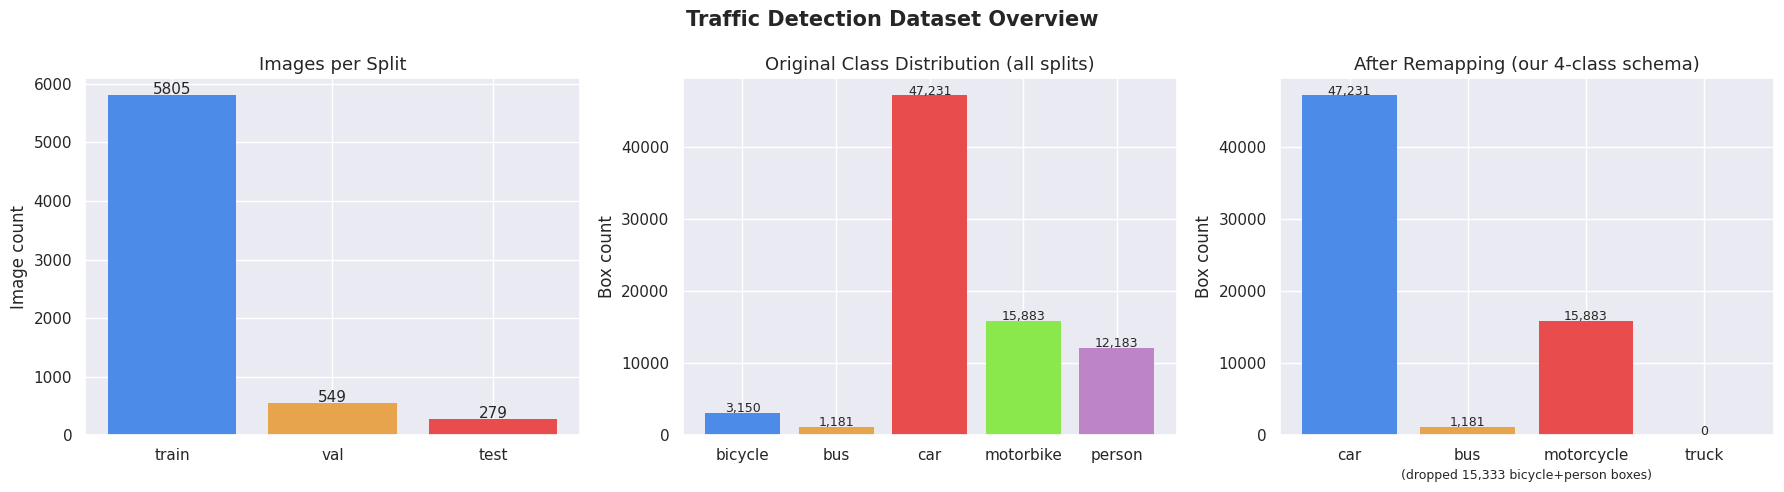

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Per-split image counts
split_names  = list(splits.keys())
split_counts = [splits[s]['n_imgs'] for s in split_names]
axes[0].bar(split_names, split_counts, color=['#4c8be8', '#e8a44c', '#e84c4c'], edgecolor='none')
axes[0].set_title('Images per Split', fontsize=13)
axes[0].set_ylabel('Image count')
for i, v in enumerate(split_counts):
    axes[0].text(i, v + 20, str(v), ha='center', fontsize=11)

# Original class distribution (all splits combined)
all_counts = Counter()
for s in splits.values():
    all_counts.update(s['counts'])
orig_names = [ORIG_CLASSES.get(i, str(i)) for i in range(5)]
orig_vals  = [all_counts.get(i, 0) for i in range(5)]
colors5    = ['#4c8be8', '#e8a44c', '#e84c4c', '#8be84c', '#be84c8']
bars = axes[1].bar(orig_names, orig_vals, color=colors5, edgecolor='none')
axes[1].set_title('Original Class Distribution (all splits)', fontsize=13)
axes[1].set_ylabel('Box count')
for bar, val in zip(bars, orig_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{val:,}', ha='center', fontsize=9)

# After remapping (drop bicycle & person)
remapped = Counter()
for orig_cls, our_cls in REMAP.items():
    remapped[our_cls] += all_counts.get(orig_cls, 0)
our_names = [OUR_CLASSES[i] for i in range(4)]
our_vals  = [remapped.get(i, 0) for i in range(4)]
bars2 = axes[2].bar(our_names, our_vals, color=CLASS_COLORS, edgecolor='none')
axes[2].set_title('After Remapping (our 4-class schema)', fontsize=13)
axes[2].set_ylabel('Box count')
dropped = all_counts.get(0, 0) + all_counts.get(4, 0)
axes[2].set_xlabel(f'(dropped {dropped:,} bicycle+person boxes)', fontsize=9)
for bar, val in zip(bars2, our_vals):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{val:,}', ha='center', fontsize=9)

plt.suptitle('Traffic Detection Dataset Overview', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{DRIVE_BASE}/datasets/01_dataset_overview.png', dpi=120, bbox_inches='tight')
plt.show()

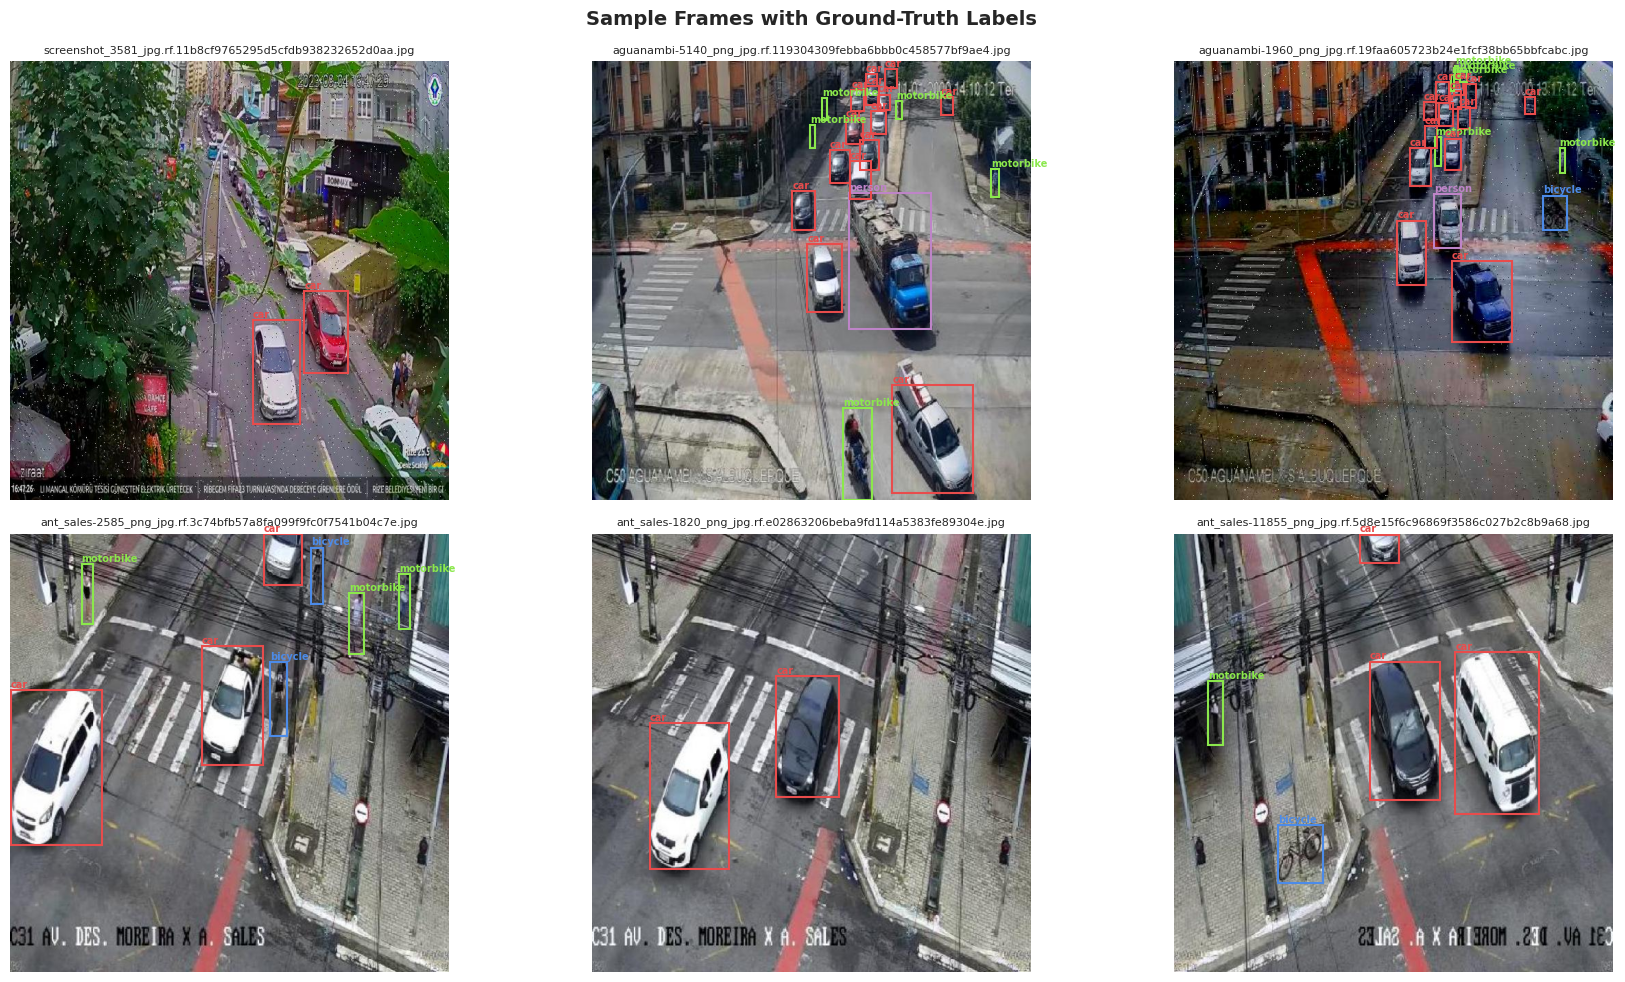

In [8]:
# Show 6 random training images with bounding boxes from existing YOLO labels

train_img_dir = splits['train']['dir'] / 'images'
train_lbl_dir = splits['train']['dir'] / 'labels'

img_files = sorted(train_img_dir.glob('*.jpg'))
sample_imgs = random.sample(img_files, min(6, len(img_files)))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_imgs):
    lbl_path = train_lbl_dir / (img_path.stem + '.txt')
    img_bgr  = cv2.imread(str(img_path))
    if img_bgr is None:
        ax.axis('off')
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w    = img_bgr.shape[:2]
    ax.imshow(img_rgb)

    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls_id, cx, cy, bw, bh = int(parts[0]), *map(float, parts[1:])
            x1 = (cx - bw/2) * w
            y1 = (cy - bh/2) * h
            bw_px = bw * w
            bh_px = bh * h
            color = colors5[cls_id] if cls_id < len(colors5) else '#ffffff'
            rect  = patches.Rectangle((x1, y1), bw_px, bh_px,
                                       linewidth=1.5, edgecolor=color, facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, y1 - 3, ORIG_CLASSES.get(cls_id, str(cls_id)),
                    color=color, fontsize=7, fontweight='bold')

    ax.set_title(img_path.name, fontsize=8)
    ax.axis('off')

plt.suptitle('Sample Frames with Ground-Truth Labels', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{DRIVE_BASE}/datasets/02_sample_frames.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Remap Classes & Build Final YOLO Dataset

The dataset already has YOLO-format labels — no XML conversion needed.  
We just need to:
1. Remap class IDs to our 4-class schema (`car=0, bus=1, motorcycle=2, truck=3`)
2. Drop `bicycle` and `person` boxes
3. Copy to a clean output directory with standard `train/val/test` naming
4. Write our `dataset.yaml`

In [9]:
def remap_label_file(src: Path, dst: Path, remap: dict) -> int:
    """Copy label file with remapped class IDs. Returns number of boxes kept."""
    kept = []
    for line in src.read_text().splitlines():
        parts = line.strip().split()
        if len(parts) != 5:
            continue
        orig_cls = int(parts[0])
        if orig_cls not in remap:
            continue   # drop this class
        new_cls = remap[orig_cls]
        kept.append(f'{new_cls} {parts[1]} {parts[2]} {parts[3]} {parts[4]}')
    dst.write_text('\n'.join(kept))
    return len(kept)

In [10]:
# Create output dirs
for split in ('train', 'val', 'test'):
    (Path(OUT_DIR) / 'images' / split).mkdir(parents=True, exist_ok=True)
    (Path(OUT_DIR) / 'labels' / split).mkdir(parents=True, exist_ok=True)

# Source split dirs: train->train, val->valid, test->test
SRC_MAP = {'train': 'train', 'val': 'valid', 'test': 'test'}

remap_stats = {split: Counter() for split in ('train', 'val', 'test')}
total_imgs   = 0
total_kept   = 0
total_dropped = 0

for our_split, src_name in SRC_MAP.items():
    src_dir   = _raw / src_name
    img_src   = src_dir / 'images'
    lbl_src   = src_dir / 'labels'
    img_dst   = Path(OUT_DIR) / 'images' / our_split
    lbl_dst   = Path(OUT_DIR) / 'labels' / our_split

    if not img_src.exists():
        print(f'  [skip] {src_dir} not found')
        continue

    img_files = sorted(img_src.glob('*.jpg'))
    for img_path in tqdm(img_files, desc=our_split):
        lbl_path = lbl_src / (img_path.stem + '.txt')
        if not lbl_path.exists():
            continue

        # Remap label
        n_kept = remap_label_file(lbl_path, lbl_dst / lbl_path.name, REMAP)

        # Count originals for stats
        orig_lines = [l for l in lbl_path.read_text().splitlines() if l.strip()]
        total_dropped += len(orig_lines) - n_kept
        total_kept    += n_kept

        # Copy image
        shutil.copy2(img_path, img_dst / img_path.name)
        total_imgs += 1

        # Accumulate class stats
        for line in (lbl_dst / lbl_path.name).read_text().splitlines():
            parts = line.strip().split()
            if parts:
                remap_stats[our_split][int(parts[0])] += 1

print('\nRemap complete.')
print(f'  Images copied  : {total_imgs:,}')
print(f'  Boxes kept     : {total_kept:,}')
print(f'  Boxes dropped  : {total_dropped:,} (bicycle + person)')
for split in ('train', 'val', 'test'):
    imgs = list((Path(OUT_DIR) / 'images' / split).glob('*.jpg'))
    print(f'  {split:5s}: {len(imgs):,} images | {dict(remap_stats[split])}')

train:   0%|          | 0/5805 [00:00<?, ?it/s]

val:   0%|          | 0/549 [00:00<?, ?it/s]

test:   0%|          | 0/279 [00:00<?, ?it/s]


Remap complete.
  Images copied  : 6,633
  Boxes kept     : 64,295
  Boxes dropped  : 15,333 (bicycle + person)
  train: 5,805 images | {2: 13995, 0: 41478, 1: 1032}
  val  : 549 images | {2: 1238, 0: 3842, 1: 108}
  test : 279 images | {2: 650, 0: 1911, 1: 41}


## 6. Write dataset.yaml

In [11]:
dataset_yaml = f"""# Traffic Detection dataset (remapped to 4-class schema)
# Source: yusufberksardoan/traffic-detection-project (Kaggle)
# Generated by 01_data_exploration.ipynb

path: {OUT_DIR}
train: images/train
val:   images/val
test:  images/test

nc: 4
names:
  0: car
  1: bus
  2: motorcycle
  3: truck
"""

yaml_path = Path(OUT_DIR) / 'dataset.yaml'
yaml_path.write_text(dataset_yaml)
print('Written:', yaml_path)
print()
print(yaml_path.read_text())

Written: /content/traffic_yolo/dataset.yaml

# Traffic Detection dataset (remapped to 4-class schema)
# Source: yusufberksardoan/traffic-detection-project (Kaggle)
# Generated by 01_data_exploration.ipynb

path: /content/traffic_yolo
train: images/train
val:   images/val
test:  images/test

nc: 4
names:
  0: car
  1: bus
  2: motorcycle
  3: truck



## 7. Class Distribution & BBox Stats Visualizations

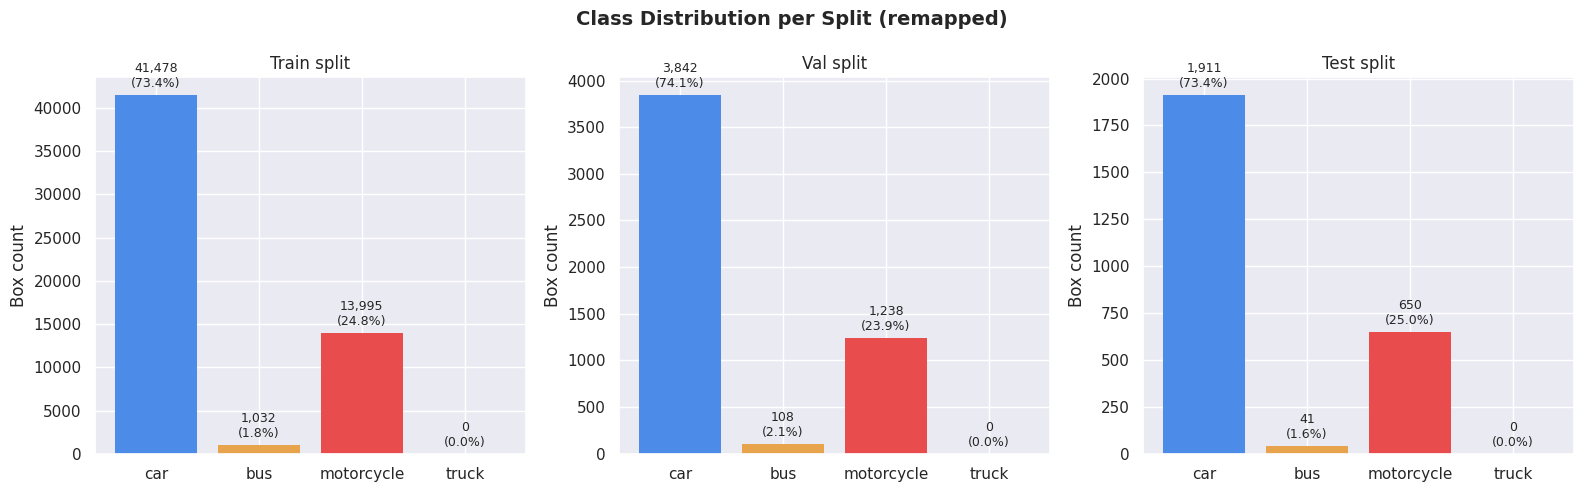

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
our_names = [OUR_CLASSES[i] for i in range(4)]

for ax, split in zip(axes, ('train', 'val', 'test')):
    counts = [remap_stats[split].get(i, 0) for i in range(4)]
    bars = ax.bar(our_names, counts, color=CLASS_COLORS, edgecolor='none')
    ax.set_title(f'{split.capitalize()} split', fontsize=12)
    ax.set_ylabel('Box count')
    total = sum(counts)
    for bar, val in zip(bars, counts):
        pct = val / total * 100 if total else 0
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + total*0.01,
                f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=9)

plt.suptitle('Class Distribution per Split (remapped)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{DRIVE_BASE}/datasets/03_class_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

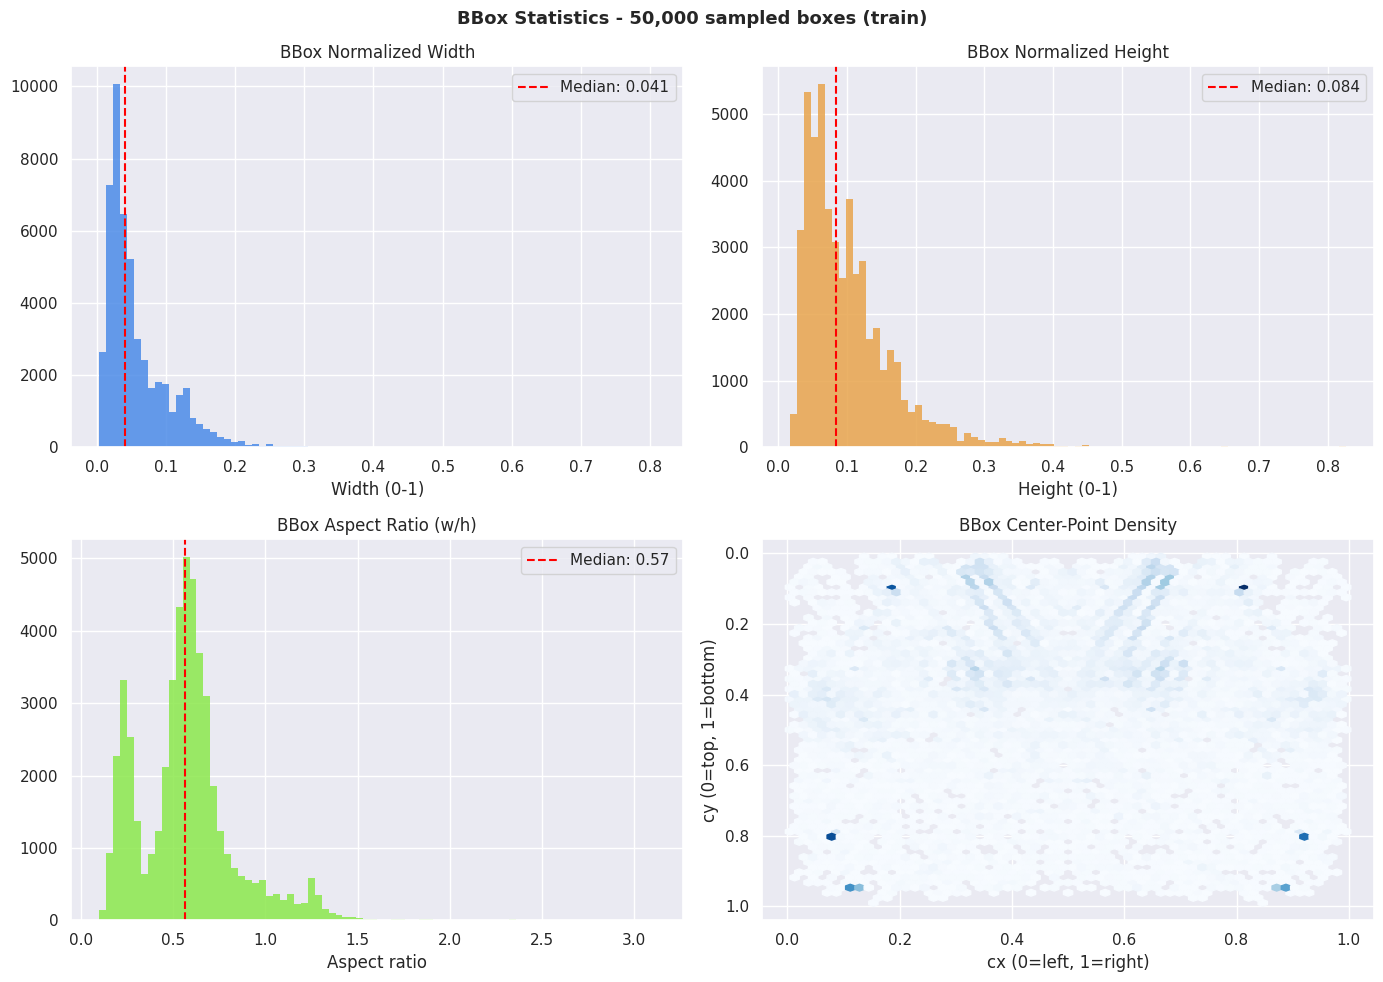

Width  - mean: 0.058, median: 0.041
Height - mean: 0.102, median: 0.084


In [13]:
MAX_SAMPLE = 50_000
ww, hh, cx_vals, cy_vals = [], [], [], []

train_label_dir = Path(OUT_DIR) / 'labels' / 'train'
label_files = list(train_label_dir.glob('*.txt'))
random.shuffle(label_files)

collected = 0
for lf in label_files:
    if collected >= MAX_SAMPLE:
        break
    for line in lf.read_text().splitlines():
        parts = line.strip().split()
        if len(parts) == 5:
            _, cx, cy, w, h = map(float, parts)
            ww.append(w); hh.append(h)
            cx_vals.append(cx); cy_vals.append(cy)
            collected += 1
            if collected >= MAX_SAMPLE:
                break

ww, hh = np.array(ww), np.array(hh)
cx_vals, cy_vals = np.array(cx_vals), np.array(cy_vals)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(ww, bins=80, color='#4c8be8', edgecolor='none', alpha=0.85)
axes[0, 0].set_title('BBox Normalized Width', fontsize=12)
axes[0, 0].set_xlabel('Width (0-1)')
axes[0, 0].axvline(np.median(ww), color='red', linestyle='--',
                    label=f'Median: {np.median(ww):.3f}')
axes[0, 0].legend()

axes[0, 1].hist(hh, bins=80, color='#e8a44c', edgecolor='none', alpha=0.85)
axes[0, 1].set_title('BBox Normalized Height', fontsize=12)
axes[0, 1].set_xlabel('Height (0-1)')
axes[0, 1].axvline(np.median(hh), color='red', linestyle='--',
                    label=f'Median: {np.median(hh):.3f}')
axes[0, 1].legend()

aspect = ww / np.maximum(hh, 1e-6)
axes[1, 0].hist(aspect, bins=80, color='#8be84c', edgecolor='none', alpha=0.85)
axes[1, 0].set_title('BBox Aspect Ratio (w/h)', fontsize=12)
axes[1, 0].set_xlabel('Aspect ratio')
axes[1, 0].axvline(np.median(aspect), color='red', linestyle='--',
                    label=f'Median: {np.median(aspect):.2f}')
axes[1, 0].legend()

axes[1, 1].hexbin(cx_vals, cy_vals, gridsize=60, cmap='Blues', mincnt=1)
axes[1, 1].set_title('BBox Center-Point Density', fontsize=12)
axes[1, 1].set_xlabel('cx (0=left, 1=right)')
axes[1, 1].set_ylabel('cy (0=top, 1=bottom)')
axes[1, 1].invert_yaxis()

plt.suptitle(f'BBox Statistics - {collected:,} sampled boxes (train)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{DRIVE_BASE}/datasets/04_bbox_stats.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Width  - mean: {ww.mean():.3f}, median: {np.median(ww):.3f}')
print(f'Height - mean: {hh.mean():.3f}, median: {np.median(hh):.3f}')

## 8. Extract Sample Clips for Local Demo

The dataset contains individual images, not video. We group images by filename prefix (traffic camera ID) and encode them as MP4 clips for the live demo.

In [14]:
# Images are named like: <camera_id>_<frame>.jpg  e.g. 20230514_084501_000001.jpg
# Group by camera/scene prefix (first segment before last underscore)
from collections import defaultdict

train_img_dir = Path(OUT_DIR) / 'images' / 'train'
img_files = sorted(train_img_dir.glob('*.jpg'))

# Group by filename prefix (everything except the last numeric segment)
groups = defaultdict(list)
for f in img_files:
    # Split on underscore, use all but last part as group key
    parts = f.stem.rsplit('_', 1)
    key   = parts[0] if len(parts) == 2 else f.stem
    groups[key].append(f)

# Sort groups by size (prefer longer sequences for better clips)
sorted_groups = sorted(groups.items(), key=lambda x: len(x[1]), reverse=True)

print(f'Found {len(groups)} unique scenes/prefixes in train set.')
print(f'Top 5 by frame count:')
for name, frames in sorted_groups[:5]:
    print(f'  {name}: {len(frames)} frames')

# Pick top 3
CLIP_GROUPS = sorted_groups[:3]
print(f'\nSelected for sample clips: {[g[0] for g in CLIP_GROUPS]}')

Found 1359 unique scenes/prefixes in train set.
Top 5 by frame count:
  image04_png: 18 frames
  image06_png: 18 frames
  image14_png: 18 frames
  image22_png: 18 frames
  image57_png: 18 frames

Selected for sample clips: ['image04_png', 'image06_png', 'image14_png']


In [15]:
MAX_FRAMES_PER_CLIP = 300
FPS = 15

os.makedirs(CLIP_DIR, exist_ok=True)
encoded = []

for group_name, frame_paths in CLIP_GROUPS:
    frame_paths = sorted(frame_paths)[:MAX_FRAMES_PER_CLIP]
    out_path    = Path(CLIP_DIR) / f'{group_name}.mp4'

    first = cv2.imread(str(frame_paths[0]))
    if first is None:
        print(f'  [skip] cannot read {frame_paths[0]}')
        continue
    h, w = first.shape[:2]

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(str(out_path), fourcc, FPS, (w, h))
    for fp in tqdm(frame_paths, desc=group_name, leave=False):
        frame = cv2.imread(str(fp))
        if frame is not None:
            writer.write(frame)
    writer.release()

    size_mb = out_path.stat().st_size / 1e6
    print(f'  {out_path.name}  — {len(frame_paths)} frames, {size_mb:.1f} MB')
    encoded.append(out_path)

print(f'\nEncoded {len(encoded)} clips.')

image04_png:   0%|          | 0/18 [00:00<?, ?it/s]

  image04_png.mp4  — 18 frames, 2.5 MB


image06_png:   0%|          | 0/18 [00:00<?, ?it/s]

  image06_png.mp4  — 18 frames, 2.2 MB


image14_png:   0%|          | 0/18 [00:00<?, ?it/s]

  image14_png.mp4  — 18 frames, 1.9 MB

Encoded 3 clips.


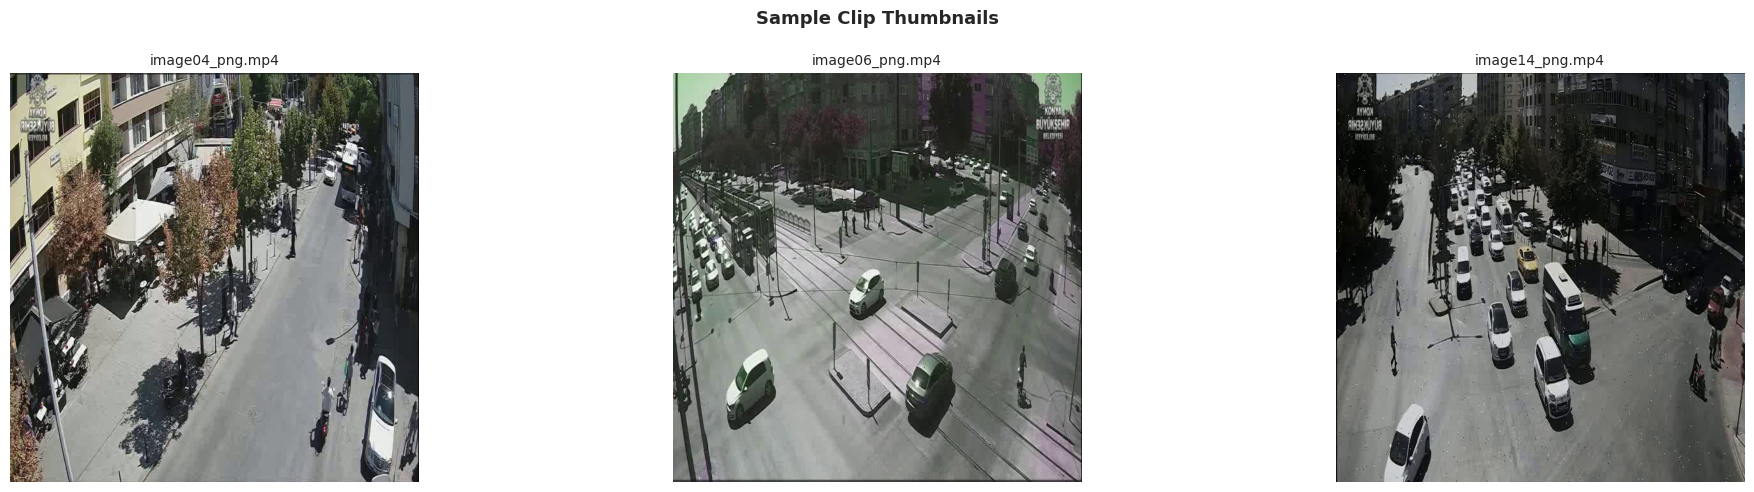

In [16]:
# ── Show first frame of each clip ─────────────────────────────────────────────
fig, axes = plt.subplots(1, len(encoded), figsize=(7 * len(encoded), 5))
if len(encoded) == 1:
    axes = [axes]

for ax, clip_path in zip(axes, encoded):
    cap = cv2.VideoCapture(str(clip_path))
    ret, frame = cap.read()
    cap.release()
    if ret:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(clip_path.name, fontsize=10)
    ax.axis('off')

plt.suptitle('Sample Clip Thumbnails', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Save Everything to Google Drive

In [17]:
print(f'Copying YOLO dataset to Drive: {DRIVE_DATASET_DIR} ...')
shutil.copytree(OUT_DIR, DRIVE_DATASET_DIR, dirs_exist_ok=True)

for split in ('train', 'val', 'test'):
    n_imgs = len(list((Path(DRIVE_DATASET_DIR) / 'images' / split).glob('*.jpg')))
    n_lbls = len(list((Path(DRIVE_DATASET_DIR) / 'labels' / split).glob('*.txt')))
    print(f'  {split:5s}: {n_imgs:,} images, {n_lbls:,} labels')
print('Dataset saved to Drive.')

Copying YOLO dataset to Drive: /content/drive/MyDrive/TrafficVision/datasets/traffic_yolo ...
  train: 5,805 images, 5,805 labels
  val  : 549 images, 549 labels
  test : 279 images, 279 labels
Dataset saved to Drive.


In [18]:
print(f'Copying sample clips to Drive: {DRIVE_SAMPLE_DIR} ...')
for clip_path in encoded:
    dst = Path(DRIVE_SAMPLE_DIR) / clip_path.name
    shutil.copy2(clip_path, dst)
    print(f'  Saved: {dst}')
print('Clips saved.')

Copying sample clips to Drive: /content/drive/MyDrive/TrafficVision/sample_clips ...
  Saved: /content/drive/MyDrive/TrafficVision/sample_clips/image04_png.mp4
  Saved: /content/drive/MyDrive/TrafficVision/sample_clips/image06_png.mp4
  Saved: /content/drive/MyDrive/TrafficVision/sample_clips/image14_png.mp4
Clips saved.


In [19]:
manifest = {
    'dataset_slug': 'yusufberksardoan/traffic-detection-project',
    'class_names': ['car', 'bus', 'motorcycle', 'truck'],
    'class_remap': {
        'original': {0: 'bicycle', 1: 'bus', 2: 'car', 3: 'motorbike', 4: 'person'},
        'mapping':  {'2->0': 'car', '1->1': 'bus', '3->2': 'motorcycle'},
        'dropped':  ['bicycle (0)', 'person (4)'],
    },
    'split_counts': {
        split: {
            'images': len(list((Path(OUT_DIR) / 'images' / split).glob('*.jpg'))),
            'labels': len(list((Path(OUT_DIR) / 'labels' / split).glob('*.txt'))),
        }
        for split in ('train', 'val', 'test')
    },
    'sample_clips': [p.name for p in encoded],
}

manifest_path = Path(DRIVE_BASE) / 'datasets' / 'dataset_manifest.json'
manifest_path.write_text(json.dumps(manifest, indent=2))
print('Manifest saved to:', manifest_path)
print(json.dumps(manifest, indent=2))

Manifest saved to: /content/drive/MyDrive/TrafficVision/datasets/dataset_manifest.json
{
  "dataset_slug": "yusufberksardoan/traffic-detection-project",
  "class_names": [
    "car",
    "bus",
    "motorcycle",
    "truck"
  ],
  "class_remap": {
    "original": {
      "0": "bicycle",
      "1": "bus",
      "2": "car",
      "3": "motorbike",
      "4": "person"
    },
    "mapping": {
      "2->0": "car",
      "1->1": "bus",
      "3->2": "motorcycle"
    },
    "dropped": [
      "bicycle (0)",
      "person (4)"
    ]
  },
  "split_counts": {
    "train": {
      "images": 5805,
      "labels": 5805
    },
    "val": {
      "images": 549,
      "labels": 549
    },
    "test": {
      "images": 279,
      "labels": 279
    }
  },
  "sample_clips": [
    "image04_png.mp4",
    "image06_png.mp4",
    "image14_png.mp4"
  ]
}


## Done — Phase 1 Complete

### Summary

| Item | Location (Drive) |
|------|------------------|
| YOLO dataset (remapped) | `TrafficVision/datasets/traffic_yolo/` |
| Sample clips | `TrafficVision/sample_clips/` |
| Weights dir (for Phase 2) | `TrafficVision/weights/` |
| Overview plot | `TrafficVision/datasets/01_dataset_overview.png` |
| Sample frames plot | `TrafficVision/datasets/02_sample_frames.png` |
| Class distribution plot | `TrafficVision/datasets/03_class_distribution.png` |
| BBox stats plot | `TrafficVision/datasets/04_bbox_stats.png` |

**Next:** Open `02_training.ipynb` in Colab to fine-tune YOLOv8s on this dataset.